# Real Estate Investment Advisor: Predicting Property Profitability & Future Value

**Dataset:** `india_housing_prices.csv` (250,000 listings, 23 columns)
**Targets:** (1) *Good Investment* (classification) and (2) *Estimated price after 5 years* (regression)

> **Important note.** The dataset has no historical prices, so both targets are built from stated domain rules (Section 2.4). Model scores therefore show how well the models recover those rules, not how well they predict the real market.

## 0. Setup

In [2]:
import os, json, time, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=.95)
PAL = sns.color_palette("deep")
SEED = 42

# ---- optional libraries (used automatically when installed) ----
try:
    import xgboost as xgb; HAVE_XGB = True
except ImportError: HAVE_XGB = False
try:
    import mlflow, mlflow.sklearn; HAVE_MLFLOW = True
except ImportError: HAVE_MLFLOW = False
print(f"XGBoost available: {HAVE_XGB} | MLflow available: {HAVE_MLFLOW}")


XGBoost available: False | MLflow available: False


## 1. Load & inspect the data

In [6]:
df = pd.read_csv("india_housing_cleaned.csv")
print("Shape:", df.shape)
print("Missing cells:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()), "| duplicate IDs:", int(df['ID'].duplicated().sum()))
df.head()

Shape: (250000, 49)
Missing cells: 0 | duplicate rows: 0 | duplicate IDs: 0


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Hospital_Density_Score,Price_per_BHK,Size_per_BHK,Floor_Ratio,Infrastructure_Score,City_Median_PPSF,Value_Ratio,Est_Annual_Growth,Future_Price_5Y_Lakhs,Good_Investment
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,3.0,489.760000,4740.00,1.000,71.0,9095.349615,1.136019,0.06630,675.12,0
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,1.0,65.173333,788.00,1.000,45.5,9891.685325,0.836129,0.07365,278.94,1
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,8.0,91.895000,1821.00,0.704,57.5,9070.655633,0.556344,0.06225,248.57,0
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,7.0,150.145000,1370.50,0.808,84.0,9244.904089,1.185030,0.07020,421.57,0
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,9.0,45.725000,1205.75,1.000,53.5,9368.861024,0.404771,0.06605,251.83,0


In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.50,72168.93,1.00,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.81,1300.61,500.00,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.52,9.81,1990.00,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.50,2.88,1.00,3.00,5.00,8.00,10.00


In [8]:
df.select_dtypes(exclude="number").nunique().to_frame("unique_values")

,unique_values
State,20
City,42
Locality,500
Property_Type,3
Furnished_Status,3
Public_Transport_Accessibility,3
Parking_Space,2
Security,2
Amenities,325
Facing,4


## 2. Data preprocessing & feature engineering

### 2.1 Missing values, duplicates and consistency checks

In [9]:
CURRENT_YEAR, HORIZON = 2025, 5

# duplicates / missing values (none found, but handled so the notebook is reusable)
df = df.drop_duplicates().drop_duplicates(subset="ID")
for c in df.select_dtypes("number"): df[c] = df[c].fillna(df[c].median())
for c in df.select_dtypes(exclude="number"): df[c] = df[c].fillna(df[c].mode().iloc[0]).astype(str).str.strip()

# Age_of_Property should equal CURRENT_YEAR - Year_Built
print("Age column consistent with Year_Built:", ((CURRENT_YEAR - df.Year_Built) == df.Age_of_Property).all())
df["Age_of_Property"] = CURRENT_YEAR - df["Year_Built"]

# logical check: floor number above building height
df["Floor_Inconsistent"] = (df.Floor_No > df.Total_Floors).astype(int)
print(f"Rows where Floor_No > Total_Floors: {df.Floor_Inconsistent.mean():.1%}  (flagged, not deleted)")

# The source Price_per_SqFt is in lakhs rounded to 2 decimals -> recompute in rupees
df["Price_per_SqFt_Rs"] = df.Price_in_Lakhs * 1e5 / df.Size_in_SqFt
print("Price per sq ft (Rs):"); print(df.Price_per_SqFt_Rs.describe().round(0))

Age column consistent with Year_Built: True
Rows where Floor_No > Total_Floors: 46.5%  (flagged, not deleted)
Price per sq ft (Rs):
count    250000.0
mean      13058.0
std       13072.0
min         202.0
25%        4803.0
50%        9245.0
75%       15987.0
max       99182.0
Name: Price_per_SqFt_Rs, dtype: float64


### 2.2 Outlier detection (IQR rule)

In [11]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

rows = []
for c in ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_Rs"]:
    lo, hi = iqr_bounds(df[c]); flag = ((df[c] < lo) | (df[c] > hi)).astype(int)
    df[f"Outlier_{c}"] = flag
    rows.append([c, round(lo), round(hi), int(flag.sum()), f"{flag.mean():.1%}"])
pd.DataFrame(rows, columns=["column", "lower bound", "upper bound", "n outliers", "share"])

,column,lower bound,upper bound,n outliers,share
0,Price_in_Lakhs,-234,743,0,0.0%
1,Size_in_SqFt,-1754,7250,0,0.0%
2,Price_per_SqFt_Rs,-11974,32764,19723,7.9%


Outliers are only found in price per sq ft (small, expensive listings). They are valid records, so they are **flagged, not removed**.

### 2.3 Feature engineering & encoding

In [13]:
AMENITIES = ["Playground", "Gym", "Garden", "Pool", "Clubhouse"]
for a in AMENITIES: df[f"Has_{a}"] = df.Amenities.str.contains(a).astype(int)
df["Amenity_Count"] = df[[f"Has_{a}" for a in AMENITIES]].sum(axis=1)
df["Parking_Flag"] = (df.Parking_Space == "Yes").astype(int)
df["Security_Flag"] = (df.Security == "Yes").astype(int)
df["Transport_Score"] = df.Public_Transport_Accessibility.map({"Low": 1, "Medium": 2, "High": 3})
df["Under_Construction"] = (df.Availability_Status == "Under_Construction").astype(int)
df["School_Density_Score"] = df.Nearby_Schools / df.Nearby_Schools.max() * 10
df["Hospital_Density_Score"] = df.Nearby_Hospitals / df.Nearby_Hospitals.max() * 10
df["Price_per_BHK"] = df.Price_in_Lakhs / df.BHK
df["Size_per_BHK"] = df.Size_in_SqFt / df.BHK
df["Floor_Ratio"] = (df.Floor_No.clip(upper=df.Total_Floors) / df.Total_Floors).round(3)

# Infrastructure score 0-100: schools 20, hospitals 20, transport 25, amenities 20, parking 7.5, security 7.5
df["Infrastructure_Score"] = (20 * df.Nearby_Schools / 10 + 20 * df.Nearby_Hospitals / 10 + 25 * (df.Transport_Score - 1) / 2
                              + 20 * df.Amenity_Count / 5 + 7.5 * df.Parking_Flag + 7.5 * df.Security_Flag)

# relative value: price/sqft vs median of same city & property type
df["City_Median_PPSF"] = df.groupby(["City", "Property_Type"]).Price_per_SqFt_Rs.transform("median")
df["Value_Ratio"] = df.Price_per_SqFt_Rs / df.City_Median_PPSF
df[["Price_per_SqFt_Rs", "Amenity_Count", "Transport_Score", "Infrastructure_Score", "Value_Ratio"]].describe().round(2)

,Price_per_SqFt_Rs,Amenity_Count,Transport_Score,Infrastructure_Score,Value_Ratio
count,250000.00,250000.00,250000.00,250000.00,250000.00
mean,13058.28,3.00,2.00,54.01,1.41
std,13071.85,1.41,0.82,15.18,1.41
min,202.25,1.00,1.00,8.00,0.02
25%,4802.84,2.00,1.00,43.50,0.52
50%,9244.75,3.00,2.00,54.00,1.00
75%,15987.39,4.00,3.00,64.50,1.73
max,99182.00,5.00,3.00,100.00,11.24


### 2.4 Target variables (domain rules)
Because the file has **no historical prices**, the targets use explicit assumptions. Change the constants below to test other assumptions.

* **Estimated annual growth** = 5% base + up to 3% from the infrastructure score + 1% if under construction (developing-area premium) + 0.5% if built within 10 years − 0.5% if older than 25 years.
* **Future price (regression target)** = `Price_in_Lakhs × (1 + growth)^5`
* **Good Investment (classification target)** = price per sq ft ≤ city & property-type median **and** growth ≥ 7% a year

In [14]:
GOOD_GROWTH_THRESHOLD = 0.07
df["Est_Annual_Growth"] = (0.05 + 0.03 * df.Infrastructure_Score / 100 + 0.01 * df.Under_Construction
                           + 0.005 * (df.Age_of_Property <= 10) - 0.005 * (df.Age_of_Property > 25))
df["Future_Price_5Y_Lakhs"] = (df.Price_in_Lakhs * (1 + df.Est_Annual_Growth) ** HORIZON).round(2)
df["Good_Investment"] = ((df.Value_Ratio <= 1.0) & (df.Est_Annual_Growth >= GOOD_GROWTH_THRESHOLD)).astype(int)

print(f"Growth range: {df.Est_Annual_Growth.min():.2%} - {df.Est_Annual_Growth.max():.2%}")
print(f"Good Investment share: {df.Good_Investment.mean():.1%}")
print(f"Mean price today: {df.Price_in_Lakhs.mean():.1f} lakhs -> mean after 5 years: {df.Future_Price_5Y_Lakhs.mean():.1f} lakhs")
df.to_csv("india_housing_cleaned.csv", index=False)
print("Saved: india_housing_cleaned.csv", df.shape)

Growth range: 4.74% - 9.50%
Good Investment share: 27.7%
Mean price today: 254.6 lakhs -> mean after 5 years: 359.0 lakhs
Saved: india_housing_cleaned.csv (250000, 49)


## 3. Exploratory Data Analysis (20 questions)

Tests used: ANOVA / t-test for group differences, Pearson / Spearman for relationships. With 250,000 rows even tiny differences can be 'significant', so the size of each difference (%) is reported as well.

In [15]:
def anova(col, y="Price_per_SqFt_Rs"):
    return stats.f_oneway(*[g[y].values for _, g in df.groupby(col)])
def p_txt(p): return "p < 0.001" if p < .001 else f"p = {p:.2f}"

### 3.1 Price & size analysis (Q1–Q5)

**Q1. Distribution of property prices**

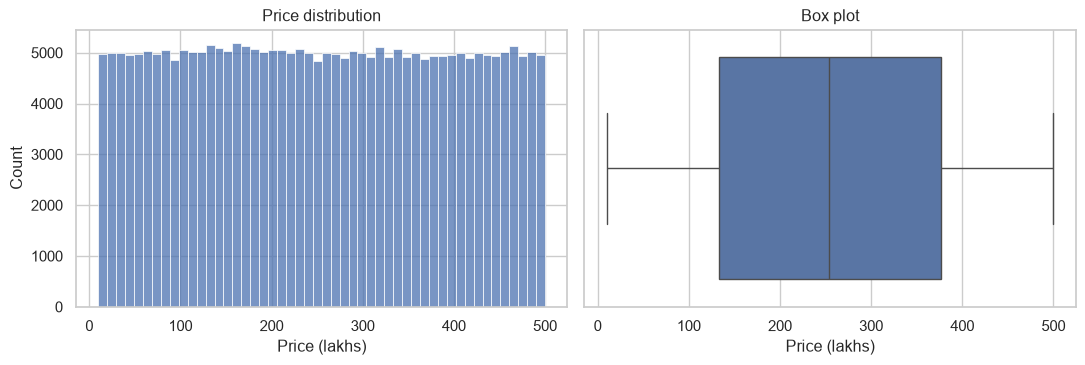

count    250000.0
mean        254.6
std         141.3
min          10.0
25%         132.6
50%         253.9
75%         376.9
max         500.0
skewness: 0.008


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df.Price_in_Lakhs, bins=50, ax=ax[0], color=PAL[0]); ax[0].set(title="Price distribution", xlabel="Price (lakhs)")
sns.boxplot(x=df.Price_in_Lakhs, ax=ax[1], color=PAL[0]); ax[1].set(title="Box plot", xlabel="Price (lakhs)")
plt.tight_layout(); plt.show()
print(df.Price_in_Lakhs.describe().round(1).to_string()); print("skewness:", round(df.Price_in_Lakhs.skew(), 3))

**Answer:** Prices run from 10 to 500 lakhs (mean 254.6, median 253.9, sd 141.3). The distribution is flat (uniform) and symmetric (skewness ≈ 0.01), with no typical price band.

**Q2. Distribution of property sizes**

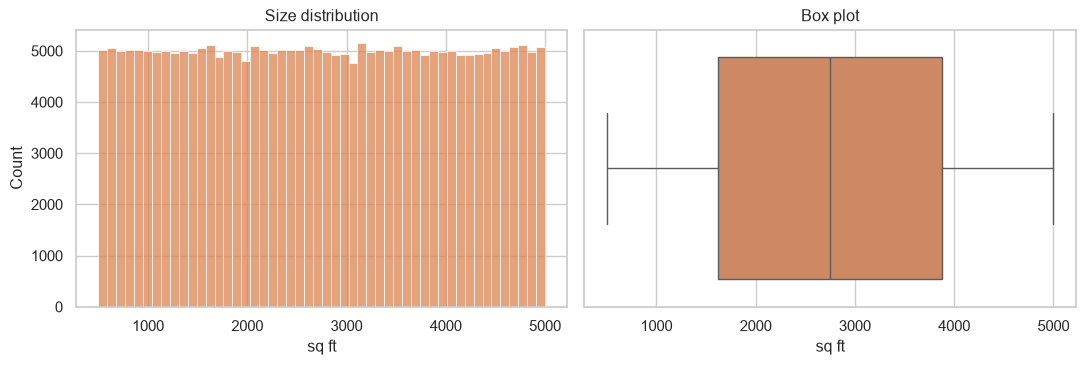

count    250000.0
mean       2749.8
std        1300.6
min         500.0
25%        1623.0
50%        2747.0
75%        3874.0
max        5000.0


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df.Size_in_SqFt, bins=50, ax=ax[0], color=PAL[1]); ax[0].set(title="Size distribution", xlabel="sq ft")
sns.boxplot(x=df.Size_in_SqFt, ax=ax[1], color=PAL[1]); ax[1].set(title="Box plot", xlabel="sq ft")
plt.tight_layout(); plt.show()
print(df.Size_in_SqFt.describe().round(1).to_string())

**Answer:** Sizes run from 500 to 5,000 sq ft (mean 2,750, median 2,747, sd 1,301). Again uniform and symmetric (skewness ≈ 0.00).

**Q3. Price per sq ft by property type**

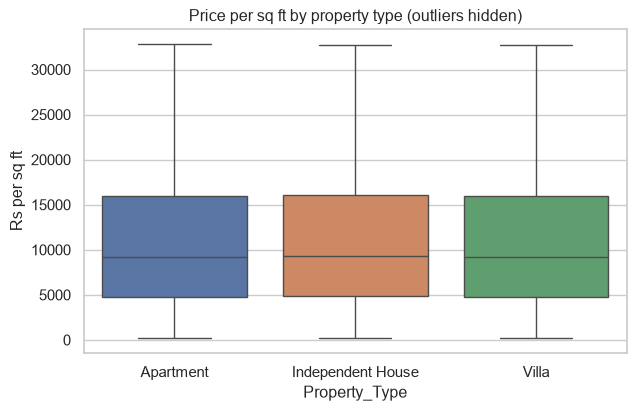

                      mean  median  count
Property_Type                            
Apartment          13047.0  9245.0  82956
Independent House  13102.0  9305.0  83300
Villa              13026.0  9190.0  83744
ANOVA p = 0.47


In [18]:
plt.figure(figsize=(7, 4.2)); sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt_Rs", hue="Property_Type", showfliers=False, legend=False)
plt.title("Price per sq ft by property type (outliers hidden)"); plt.ylabel("Rs per sq ft"); plt.show()
print(df.groupby("Property_Type").Price_per_SqFt_Rs.agg(["mean", "median", "count"]).round(0))
f, p = anova("Property_Type"); print("ANOVA", p_txt(p))

**Answer:** It does not vary. Mean price per sq ft is about ₹13,000 for Apartments, Independent Houses and Villas (differences under 1%, ANOVA p = 0.47). The mean (≈ ₹13,000) is well above the median (≈ ₹9,200) because small properties have very high price per sq ft (right skew).

**Q4. Relationship between property size and price**

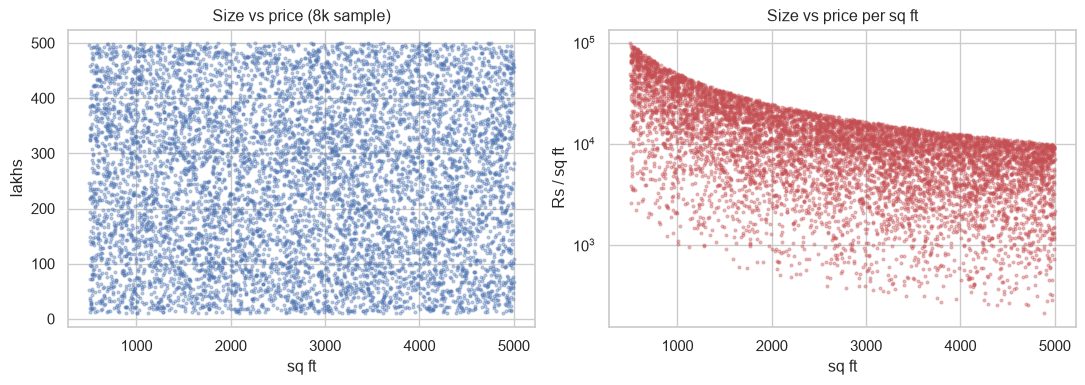

Size vs price          Pearson r = -0.0025
Size vs price per sqft Pearson r = -0.6146


In [19]:
sm = df.sample(8000, random_state=1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(sm.Size_in_SqFt, sm.Price_in_Lakhs, s=4, alpha=.35); ax[0].set(title="Size vs price (8k sample)", xlabel="sq ft", ylabel="lakhs")
ax[1].scatter(sm.Size_in_SqFt, sm.Price_per_SqFt_Rs, s=4, alpha=.35, color=PAL[3]); ax[1].set(title="Size vs price per sq ft", xlabel="sq ft", ylabel="Rs / sq ft", yscale="log")
plt.tight_layout(); plt.show()
print("Size vs price          Pearson r =", round(df.Size_in_SqFt.corr(df.Price_in_Lakhs), 4))
print("Size vs price per sqft Pearson r =", round(df.Size_in_SqFt.corr(df.Price_per_SqFt_Rs), 4))

**Answer:** No relationship between size and total price (r = −0.003). A 5,000 sq ft property is priced like a 500 sq ft one. Because of this, price per sq ft falls strongly with size (r = −0.61); this is arithmetic, not a market signal. A real market would show a clear positive link.

**Q5. Outliers in price per sq ft or size**

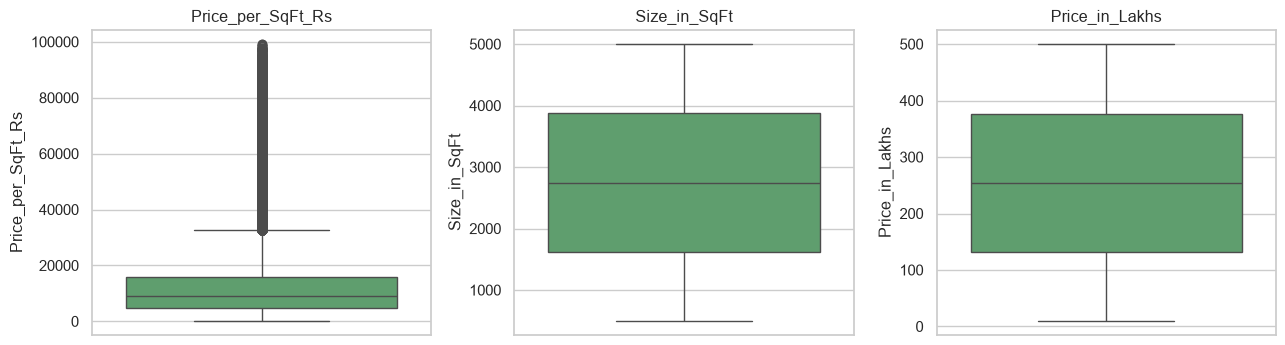

Price_per_SqFt_Rs  outliers: 19,723 (7.9%)  upper bound 32,764
Size_in_SqFt       outliers:      0 (0.0%)  upper bound 7,250
Price_in_Lakhs     outliers:      0 (0.0%)  upper bound 743
Max price per sq ft: Rs 99182 | median: 9245


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, c in zip(ax, ["Price_per_SqFt_Rs", "Size_in_SqFt", "Price_in_Lakhs"]): sns.boxplot(y=df[c], ax=a, color=PAL[2]); a.set_title(c)
plt.tight_layout(); plt.show()
for c in ["Price_per_SqFt_Rs", "Size_in_SqFt", "Price_in_Lakhs"]:
    lo, hi = iqr_bounds(df[c]); n = int(((df[c] < lo) | (df[c] > hi)).sum()); print(f"{c:18s} outliers: {n:6,d} ({n/len(df):.1%})  upper bound {hi:,.0f}")
print("Max price per sq ft: Rs", round(df.Price_per_SqFt_Rs.max()), "| median:", round(df.Price_per_SqFt_Rs.median()))

**Answer:** Size and total price have **no** outliers (both are uniformly bounded). Price per sq ft has **19,723 outliers (7.9%)** above ≈ ₹32,764/sq ft, up to ₹99,182, from small high-priced listings. They are valid, so they were flagged (`Outlier_Price_per_SqFt_Rs`), not removed.

### 3.2 Location-based analysis (Q6–Q10)

**Q6. Average price per sq ft by state**

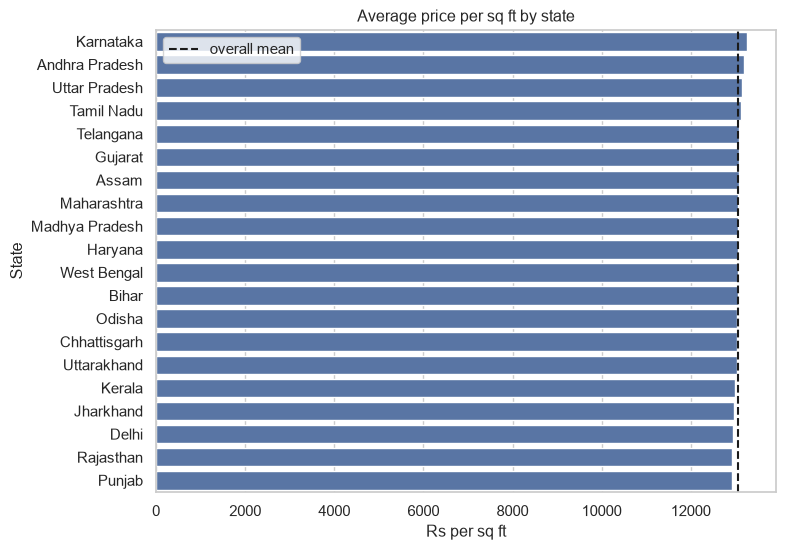

State
Karnataka         13252.0
Andhra Pradesh    13202.0
Uttar Pradesh     13143.0 
...
 State
Delhi        12941.0
Rajasthan    12932.0
Punjab       12931.0
Spread highest vs lowest: 2.5%  | ANOVA p = 0.96


In [21]:
st_ = df.groupby("State").Price_per_SqFt_Rs.mean().sort_values(ascending=False)
plt.figure(figsize=(8, 6)); sns.barplot(x=st_.values, y=st_.index, color=PAL[0]); plt.axvline(df.Price_per_SqFt_Rs.mean(), ls="--", c="k", label="overall mean")
plt.title("Average price per sq ft by state"); plt.xlabel("Rs per sq ft"); plt.legend(); plt.show()
print(st_.round(0).head(3).to_string(), "\n...\n", st_.round(0).tail(3).to_string())
print(f"Spread highest vs lowest: {st_.max()/st_.min()-1:.1%}  | ANOVA", p_txt(anova("State")[1]))

**Answer:** Highest: Karnataka (₹13,252), Andhra Pradesh (₹13,202), Uttar Pradesh (₹13,143). Lowest: Delhi (₹12,941), Rajasthan (₹12,932), Punjab (₹12,931). The gap is only 2.5% and not significant (p = 0.96), so state does not differentiate price per sq ft here.

**Q7. Average property price by city**

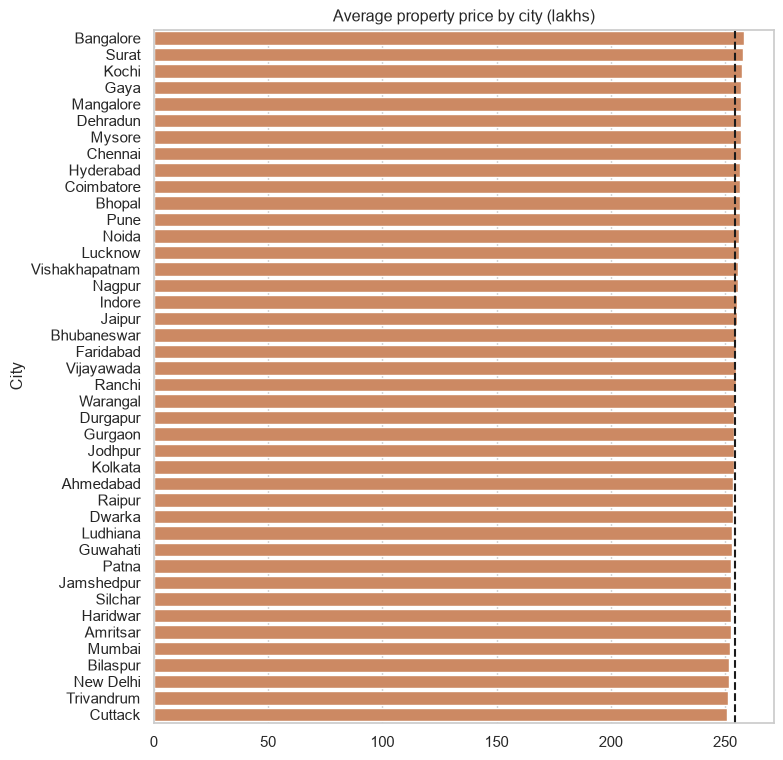

City
Bangalore    258.5
Surat        258.1
Kochi        257.4
Gaya         257.1
Mangalore    256.9 
...
 City
Mumbai        252.1
Bilaspur      251.9
New Delhi     251.6
Trivandrum    251.3
Cuttack       250.8
Spread highest vs lowest: 3.1% | ANOVA p = 0.22


In [22]:
ct = df.groupby("City").Price_in_Lakhs.mean().sort_values(ascending=False)
plt.figure(figsize=(8, 9)); sns.barplot(x=ct.values, y=ct.index, color=PAL[1]); plt.axvline(df.Price_in_Lakhs.mean(), ls="--", c="k")
plt.title("Average property price by city (lakhs)"); plt.show()
print(ct.round(1).head(5).to_string(), "\n...\n", ct.round(1).tail(5).to_string())
print(f"Spread highest vs lowest: {ct.max()/ct.min()-1:.1%} | ANOVA", p_txt(anova("City", "Price_in_Lakhs")[1]))

**Answer:** City averages sit between 250.8 lakhs (Cuttack) and 258.5 lakhs (Bangalore), around the overall mean of 254.6. The spread is 3.1% and not significant (p = 0.22). Mumbai and New Delhi are *not* pricier than small cities here, which is unlike a real market.

**Q8. Median age of properties by locality**

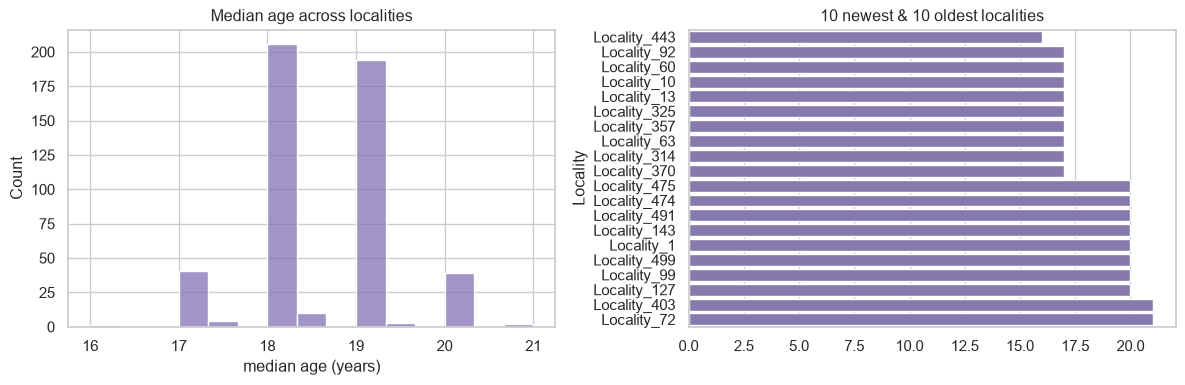

500 localities | range 16-21 yrs | median of medians 18
Oldest: {'Locality_72': 21.0, 'Locality_403': 21.0, 'Locality_75': 20.0}
Newest: {'Locality_443': 16.0, 'Locality_92': 17.0, 'Locality_60': 17.0}


In [23]:
la = df.groupby("Locality").Age_of_Property.median()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(la, bins=15, ax=ax[0], color=PAL[4]); ax[0].set(title="Median age across localities", xlabel="median age (years)")
x = pd.concat([la.sort_values().head(10), la.sort_values().tail(10)]); sns.barplot(x=x.values, y=x.index, ax=ax[1], color=PAL[4]); ax[1].set(title="10 newest & 10 oldest localities")
plt.tight_layout(); plt.show()
print(f"{la.size} localities | range {la.min():.0f}-{la.max():.0f} yrs | median of medians {la.median():.0f}")
print("Oldest:", la.sort_values(ascending=False).head(3).to_dict()); print("Newest:", la.sort_values().head(3).to_dict())

**Answer:** Across the 500 locality names the median age is 18 years (same as the overall median) and every locality falls between 16 and 21 years. Oldest: Locality_72 and Locality_403 (21 yrs); newest: Locality_443 (16 yrs). Locality names repeat across cities, so each name pools ~500 listings from many cities.

**Q9. BHK distribution across cities**

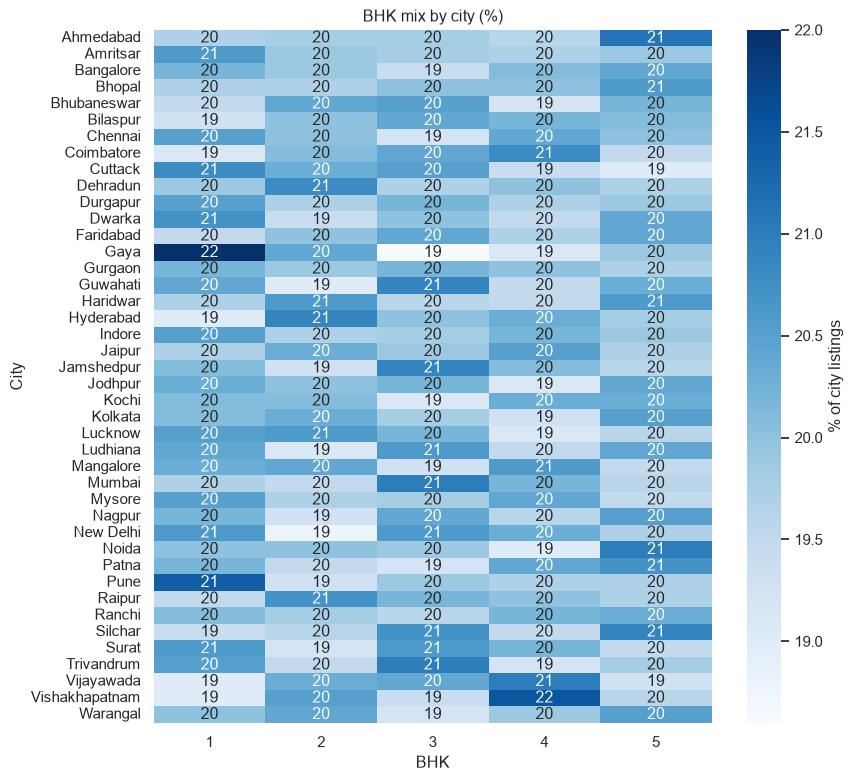

Overall BHK share (%): {1: 20.1, 2: 19.9, 3: 20.0, 4: 19.9, 5: 20.1}
Per-city BHK share range: 18.6% - 22.0% | chi-square p = 0.11


In [18]:
bc = pd.crosstab(df.City, df.BHK); bp = bc.div(bc.sum(axis=1), axis=0) * 100
plt.figure(figsize=(9, 9)); sns.heatmap(bp.round(1), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of city listings"}); plt.title("BHK mix by city (%)"); plt.show()
chi2, p, *_ = stats.chi2_contingency(bc)
print("Overall BHK share (%):", (df.BHK.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print(f"Per-city BHK share range: {bp.values.min():.1f}% - {bp.values.max():.1f}% | chi-square", p_txt(p))

**Answer:** Each BHK (1–5) is ~20% of listings overall, and every city has almost the same mix (18.6%–22.0%). A chi-square test finds no city–BHK association (p = 0.11).

**Q10. Price trends for the 5 most expensive localities**

                          avg_price   n
City        Locality                   
Pune        Locality_253      396.9  10
Patna       Locality_116      396.1  12
Bhubaneswar Locality_362      396.0  10
Mysore      Locality_153      394.3  11
Lucknow     Locality_302      392.1  12


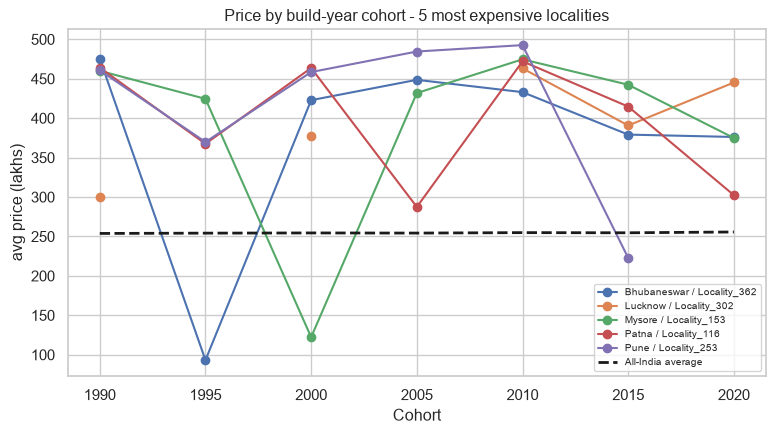

All-India average by cohort: {1990: 253.9, 1995: 254.3, 2000: 254.5, 2005: 254.3, 2010: 254.9, 2015: 254.7, 2020: 255.7}


In [19]:
# no date column -> use Year_Built cohorts (5-year bands) as a proxy for 'trend'
g = df.groupby(["City", "Locality"]).agg(avg_price=("Price_in_Lakhs", "mean"), n=("ID", "count")).query("n >= 10").sort_values("avg_price", ascending=False)
top5 = g.head(5); print(top5.round(1))
sub = df[df.set_index(["City", "Locality"]).index.isin(top5.index)].copy()
sub["Place"] = sub.City + " / " + sub.Locality; sub["Cohort"] = sub.Year_Built // 5 * 5
tr = sub.pivot_table(index="Cohort", columns="Place", values="Price_in_Lakhs", aggfunc="mean")
allm = df.assign(Cohort=df.Year_Built // 5 * 5).groupby("Cohort").Price_in_Lakhs.mean()
plt.figure(figsize=(9, 4.5)); tr.plot(marker="o", ax=plt.gca()); plt.plot(allm.index, allm.values, "k--", lw=2, label="All-India average")
plt.title("Price by build-year cohort - 5 most expensive localities"); plt.ylabel("avg price (lakhs)"); plt.legend(fontsize=7); plt.show()
print("All-India average by cohort:", allm.round(1).to_dict())

**Answer:** There is no date column, so a true time series is impossible; Year_Built cohorts were used instead. The top 5 (city/locality, ≥10 listings) are Pune/Locality_253 (397 lakhs), Patna/Locality_116 (396), Bhubaneswar/Locality_362 (396), Mysore/Locality_153 (394) and Lucknow/Locality_302 (392). Their lines zig-zag with no consistent trend, each point rests on only 1–5 listings, and the all-India line is flat (254–256 lakhs). They rank on top largely by chance from small samples.

### 3.3 Feature relationships & correlation (Q11–Q15)

**Q11. Correlation between numeric features**

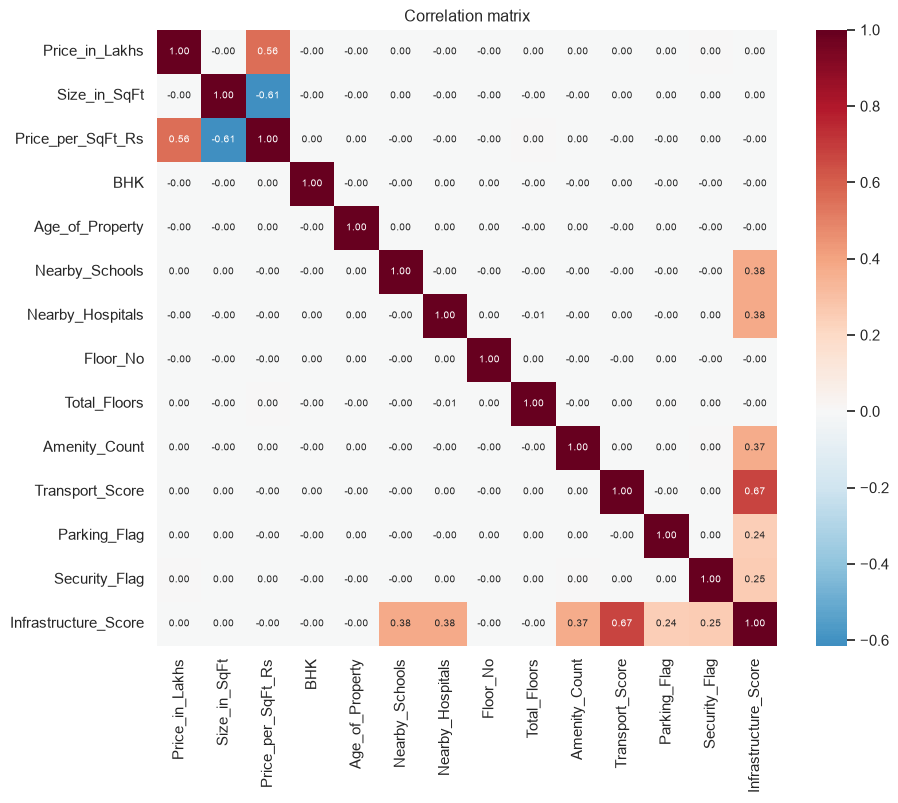

Largest |correlation| among original columns: 0.0059


In [20]:
num = ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_Rs", "BHK", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals", "Floor_No",
       "Total_Floors", "Amenity_Count", "Transport_Score", "Parking_Flag", "Security_Flag", "Infrastructure_Score"]
plt.figure(figsize=(10, 8)); sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7}); plt.title("Correlation matrix"); plt.show()
raw = ["Price_in_Lakhs", "Size_in_SqFt", "BHK", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals", "Floor_No", "Total_Floors", "Amenity_Count", "Transport_Score", "Parking_Flag", "Security_Flag"]
cr = df[raw].corr().abs().where(~np.eye(len(raw), dtype=bool)); print("Largest |correlation| among original columns:", round(cr.max().max(), 4))

**Answer:** Original columns are essentially uncorrelated (largest |r| = 0.006). The visible correlations are all built-in: Infrastructure_Score with its own parts (transport r = 0.67, schools, hospitals, amenities) and price per sq ft with size (−0.61) and price (+0.56).

**Q12. Nearby schools vs price per sq ft**

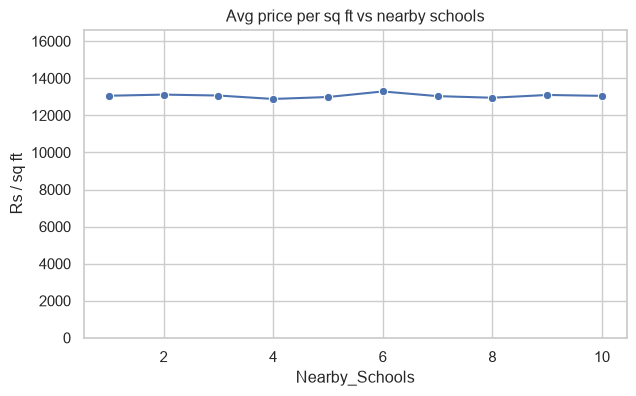

Spearman rho = -0.0023 (p = 0.26) | ANOVA p = 0.08 | range 3.1%


In [21]:
m = df.groupby("Nearby_Schools").Price_per_SqFt_Rs.mean()
plt.figure(figsize=(7, 4)); sns.lineplot(x=m.index, y=m.values, marker="o"); plt.ylim(0, m.max() * 1.25); plt.title("Avg price per sq ft vs nearby schools"); plt.ylabel("Rs / sq ft"); plt.show()
r, p = stats.spearmanr(df.Nearby_Schools, df.Price_per_SqFt_Rs); print(f"Spearman rho = {r:.4f} ({p_txt(p)}) | ANOVA", p_txt(anova('Nearby_Schools')[1]), f"| range {m.max()/m.min()-1:.1%}")

**Answer:** No relationship (Spearman ρ = −0.002, p = 0.26). Average price per sq ft stays between ₹12,888 and ₹13,292 for 1–10 schools (3.1% range, ANOVA p = 0.08).

**Q13. Nearby hospitals vs price per sq ft**

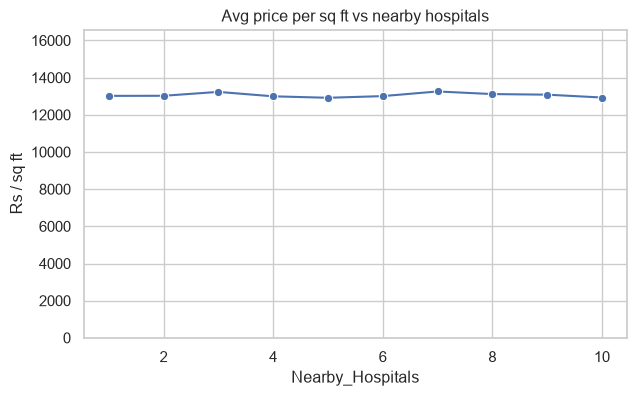

Spearman rho = -0.0017 (p = 0.39) | ANOVA p = 0.04 | range 2.6%


In [22]:
m = df.groupby("Nearby_Hospitals").Price_per_SqFt_Rs.mean()
plt.figure(figsize=(7, 4)); sns.lineplot(x=m.index, y=m.values, marker="o"); plt.ylim(0, m.max() * 1.25); plt.title("Avg price per sq ft vs nearby hospitals"); plt.ylabel("Rs / sq ft"); plt.show()
r, p = stats.spearmanr(df.Nearby_Hospitals, df.Price_per_SqFt_Rs); print(f"Spearman rho = {r:.4f} ({p_txt(p)}) | ANOVA", p_txt(anova('Nearby_Hospitals')[1]), f"| range {m.max()/m.min()-1:.1%}")

**Answer:** No practical relationship (ρ = −0.002, p = 0.39). ANOVA gives p = 0.04, but the group means show no pattern (2.6% range, not monotonic), which is expected by chance when many variables are tested on 250,000 rows.

**Q14. Price by furnished status**

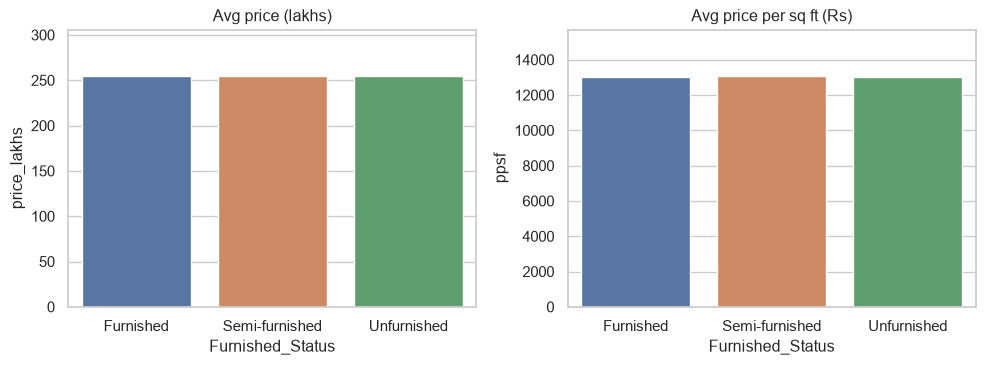

                  price_lakhs     ppsf      n
Furnished_Status                             
Furnished               254.4  13033.8  83218
Semi-furnished          254.3  13093.1  83374
Unfurnished             255.0  13047.9  83408
ANOVA price p = 0.61 | ANOVA ppsf p = 0.63


In [23]:
fs = df.groupby("Furnished_Status").agg(price_lakhs=("Price_in_Lakhs", "mean"), ppsf=("Price_per_SqFt_Rs", "mean"), n=("ID", "count")).round(1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.barplot(x=fs.index, y=fs.price_lakhs, ax=ax[0], hue=fs.index, legend=False); ax[0].set(title="Avg price (lakhs)", ylim=(0, fs.price_lakhs.max() * 1.2))
sns.barplot(x=fs.index, y=fs.ppsf, ax=ax[1], hue=fs.index, legend=False); ax[1].set(title="Avg price per sq ft (Rs)", ylim=(0, fs.ppsf.max() * 1.2)); plt.tight_layout(); plt.show()
print(fs); print("ANOVA price", p_txt(anova("Furnished_Status", "Price_in_Lakhs")[1]), "| ANOVA ppsf", p_txt(anova("Furnished_Status")[1]))

**Answer:** Not at all. Furnished 254.4, Semi-furnished 254.3, Unfurnished 255.0 lakhs (differences < 0.3%; ANOVA p = 0.61). Furnishing is not priced in.

**Q15. Price per sq ft by facing direction**

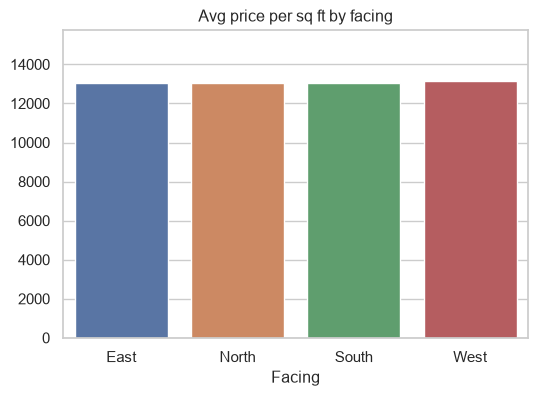

{'East': 13024.0, 'North': 13025.0, 'South': 13044.0, 'West': 13140.0} | range 0.9% | ANOVA p = 0.34


In [24]:
fc = df.groupby("Facing").Price_per_SqFt_Rs.mean().round(0)
plt.figure(figsize=(6, 4)); sns.barplot(x=fc.index, y=fc.values, hue=fc.index, legend=False); plt.ylim(0, fc.max() * 1.2); plt.title("Avg price per sq ft by facing"); plt.show()
print(fc.to_dict(), f"| range {fc.max()/fc.min()-1:.1%} | ANOVA", p_txt(anova("Facing")[1]))

**Answer:** West-facing is highest (₹13,140) and East lowest (₹13,024), a 0.9% gap that is not significant (p = 0.34). Facing has no effect.

### 3.4 Investment, amenities & ownership (Q16–Q20)

**Q16. Properties by owner type**

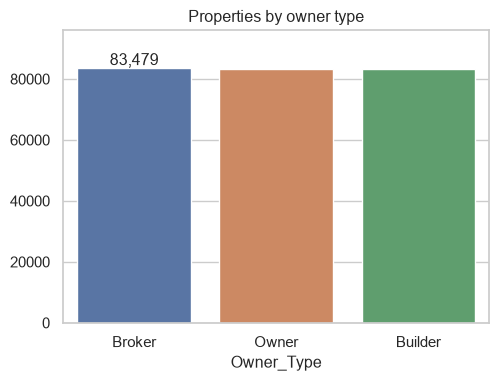

{'Broker': 33.39, 'Owner': 33.31, 'Builder': 33.3} | uniform test p = 0.83


In [25]:
v = df.Owner_Type.value_counts(); plt.figure(figsize=(5.5, 3.8)); ax = sns.barplot(x=v.index, y=v.values, hue=v.index, legend=False); ax.bar_label(ax.containers[0], fmt="{:,.0f}"); plt.title("Properties by owner type"); plt.ylim(0, v.max() * 1.15); plt.show()
print((v / len(df) * 100).round(2).to_dict(), "| uniform test", p_txt(stats.chisquare(v.values)[1]))

**Answer:** Broker 83,479 (33.4%), Owner 83,268 (33.3%), Builder 83,253 (33.3%): an even three-way split (p = 0.83).

**Q17. Properties by availability status**

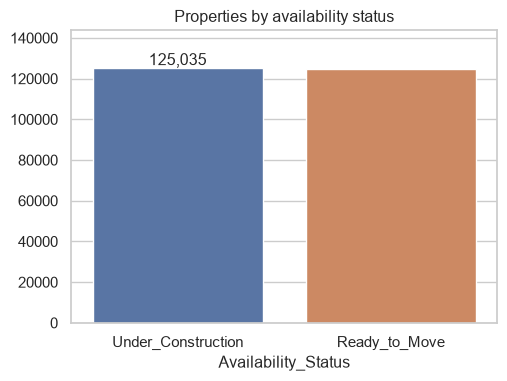

{'Under_Construction': 50.01, 'Ready_to_Move': 49.99} | uniform test p = 0.89


In [26]:
v = df.Availability_Status.value_counts(); plt.figure(figsize=(5.5, 3.8)); ax = sns.barplot(x=v.index, y=v.values, hue=v.index, legend=False); ax.bar_label(ax.containers[0], fmt="{:,.0f}"); plt.title("Properties by availability status"); plt.ylim(0, v.max() * 1.15); plt.show()
print((v / len(df) * 100).round(2).to_dict(), "| uniform test", p_txt(stats.chisquare(v.values)[1]))

**Answer:** Under Construction 125,035 (50.0%) and Ready to Move 124,965 (50.0%). The data has no 'Sold' status even though the data dictionary lists one.

**Q18. Does parking space affect price?**

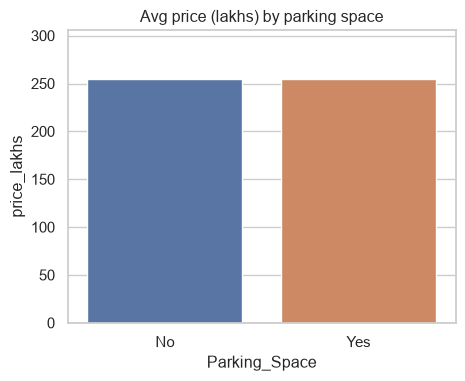

               price_lakhs     ppsf       n
Parking_Space                              
No                   254.4  13071.8  125456
Yes                  254.7  13044.7  124544
t-test p = 0.58


In [27]:
pk = df.groupby("Parking_Space").agg(price_lakhs=("Price_in_Lakhs", "mean"), ppsf=("Price_per_SqFt_Rs", "mean"), n=("ID", "count")).round(1)
plt.figure(figsize=(5, 3.8)); sns.barplot(x=pk.index, y=pk.price_lakhs, hue=pk.index, legend=False); plt.ylim(0, pk.price_lakhs.max() * 1.2); plt.title("Avg price (lakhs) by parking space"); plt.show()
print(pk); print("t-test", p_txt(stats.ttest_ind(df[df.Parking_Flag == 1].Price_in_Lakhs, df[df.Parking_Flag == 0].Price_in_Lakhs).pvalue))

**Answer:** No. Average price is 254.7 lakhs with parking vs 254.4 without (+0.12%, p = 0.58); price per sq ft is also the same. Parking is a Yes/No flag in this data, not a count.

**Q19. How do amenities affect price per sq ft?**

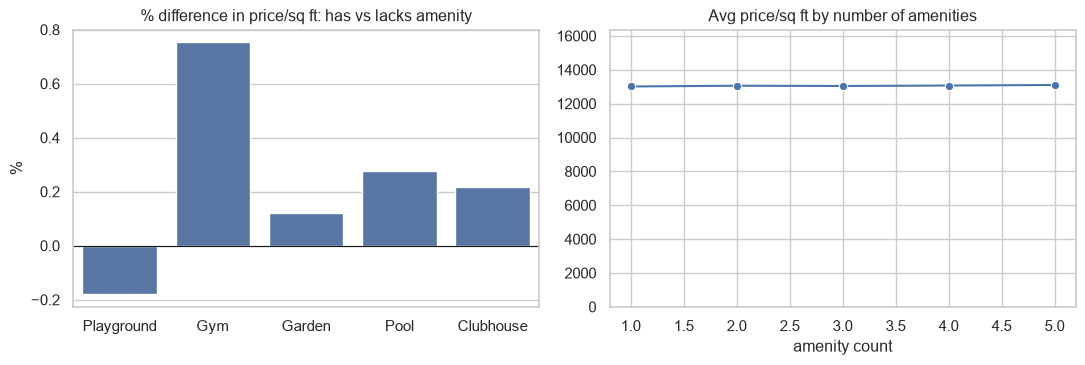

{'Playground': '-0.18% (p=0.66)', 'Gym': '+0.75% (p=0.07)', 'Garden': '+0.12% (p=0.77)', 'Pool': '+0.28% (p=0.50)', 'Clubhouse': '+0.22% (p=0.59)'}
ANOVA by amenity count p = 0.88


In [28]:
eff = {a: df[df[f"Has_{a}"] == 1].Price_per_SqFt_Rs.mean() / df[df[f"Has_{a}"] == 0].Price_per_SqFt_Rs.mean() * 100 - 100 for a in AMENITIES}
pv_ = {a: stats.ttest_ind(df[df[f"Has_{a}"] == 1].Price_per_SqFt_Rs, df[df[f"Has_{a}"] == 0].Price_per_SqFt_Rs).pvalue for a in AMENITIES}
ac = df.groupby("Amenity_Count").Price_per_SqFt_Rs.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=list(eff), y=list(eff.values()), ax=ax[0], color=PAL[0]); ax[0].axhline(0, c="k", lw=.8); ax[0].set(title="% difference in price/sq ft: has vs lacks amenity", ylabel="%")
sns.lineplot(x=ac.index, y=ac.values, marker="o", ax=ax[1]); ax[1].set(title="Avg price/sq ft by number of amenities", ylim=(0, ac.max() * 1.25), xlabel="amenity count"); plt.tight_layout(); plt.show()
print({a: f"{eff[a]:+.2f}% (p={pv_[a]:.2f})" for a in eff}); print("ANOVA by amenity count", p_txt(anova("Amenity_Count")[1]))

**Answer:** Having a given amenity changes price per sq ft by only Playground −0.18%, Gym +0.75%, Garden +0.12%, Pool +0.28%, Clubhouse +0.22%; none is significant at 5% (smallest p = 0.07, Gym). By number of amenities the line is flat (ANOVA p = 0.88). Amenities do not add to price per sq ft here.

**Q20. Public transport accessibility vs price per sq ft / investment potential**

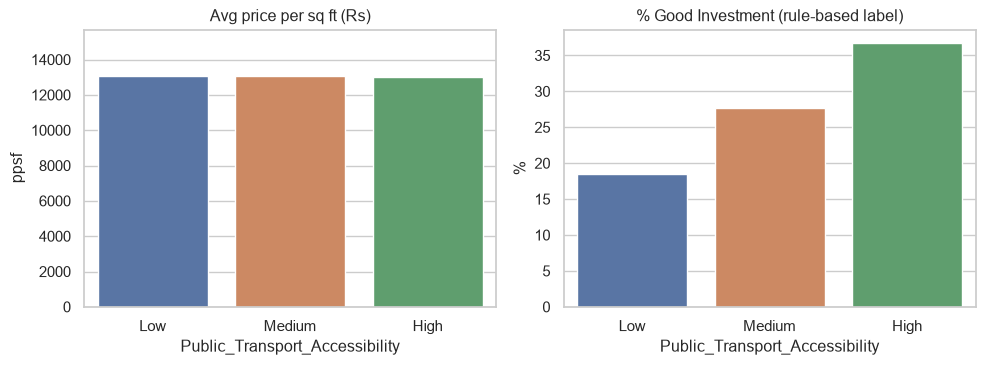

                                      ppsf  good_share  growth
Public_Transport_Accessibility                                
Low                             13085.5391      0.1848  0.0673
Medium                          13062.2331      0.2769  0.0711
High                            13027.2422      0.3677  0.0748
ANOVA price/sqft p = 0.66


In [29]:
tp = df.groupby("Public_Transport_Accessibility").agg(ppsf=("Price_per_SqFt_Rs", "mean"), good_share=("Good_Investment", "mean"), growth=("Est_Annual_Growth", "mean")).loc[["Low", "Medium", "High"]]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.barplot(x=tp.index, y=tp.ppsf, ax=ax[0], hue=tp.index, legend=False); ax[0].set(title="Avg price per sq ft (Rs)", ylim=(0, tp.ppsf.max() * 1.2))
sns.barplot(x=tp.index, y=tp.good_share * 100, ax=ax[1], hue=tp.index, legend=False); ax[1].set(title="% Good Investment (rule-based label)", ylabel="%"); plt.tight_layout(); plt.show()
print(tp.round(4)); print("ANOVA price/sqft", p_txt(anova("Public_Transport_Accessibility")[1]))

**Answer:** Price per sq ft is unrelated to transport access (≈ ₹13,030–13,090; p = 0.66). Investment potential does rise with transport: Good Investment share is 18.5% (Low), 27.7% (Medium), 36.8% (High); growth 6.73% / 7.11% / 7.48%. This follows directly from the label rules (transport is 25 of 100 infrastructure points), so it is a design assumption, not an observed market effect.

### 3.5 Extra questions from the brief

Crime-rate column in dataset: False
Area vs estimated growth (Spearman): 0.0022
Good-investment share by size quintile: [8.7, 18.5, 27.9, 37.0, 46.3]
Infrastructure score vs price per sq ft (Spearman): -0.0012
Infrastructure score vs price (Spearman): 0.0009


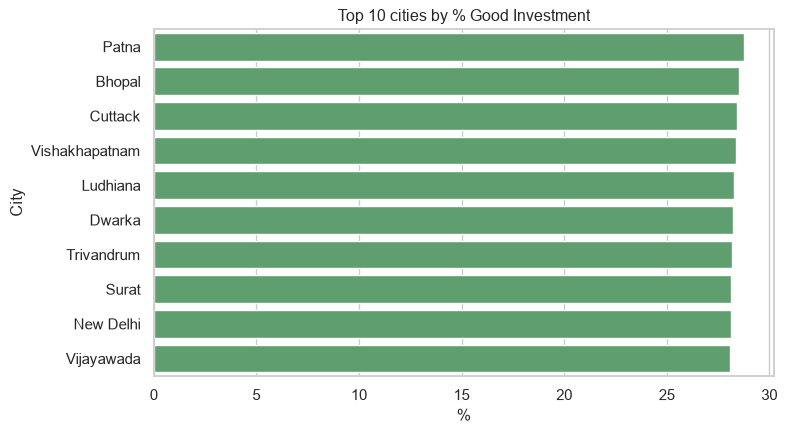

In [30]:
print("Crime-rate column in dataset:", any("crime" in c.lower() for c in df.columns))
print("Area vs estimated growth (Spearman):", round(stats.spearmanr(df.Size_in_SqFt, df.Est_Annual_Growth)[0], 4))
q = df.groupby(pd.qcut(df.Size_in_SqFt, 5)).Good_Investment.mean(); print("Good-investment share by size quintile:", (q * 100).round(1).tolist())
print("Infrastructure score vs price per sq ft (Spearman):", round(stats.spearmanr(df.Infrastructure_Score, df.Price_per_SqFt_Rs)[0], 4))
print("Infrastructure score vs price (Spearman):", round(stats.spearmanr(df.Infrastructure_Score, df.Price_in_Lakhs)[0], 4))
gc = df.groupby("City").Good_Investment.mean().sort_values(ascending=False) * 100
plt.figure(figsize=(8, 4.5)); sns.barplot(x=gc.head(10).values, y=gc.head(10).index, color=PAL[2]); plt.title("Top 10 cities by % Good Investment"); plt.xlabel("%"); plt.show()

* **Crime rate:** the dataset has no crime column, so this cannot be analysed (recommended data enhancement).
* **Area vs investment return:** no relationship with estimated growth (ρ ≈ 0.002). Larger properties are labelled Good Investment more often only because their price per sq ft is lower.
* **Infrastructure vs resale value:** no relationship with observed price (ρ ≈ 0.001); infrastructure only drives the *assumed* growth rate.
* **Location:** Good Investment share is 26–29% in every state and city, so no location is clearly better.

## 4. Model training
* Features: raw listing attributes + simple engineered features. The rule inputs (`Est_Annual_Growth`, `Infrastructure_Score`, `Value_Ratio`, `City_Median_PPSF`) are **not** given to the models, so they must learn the rules from raw attributes.
* Numeric features scaled with `StandardScaler`; categoricals one-hot encoded (inside the pipeline, fitted on training data only).
* Split 80 / 20, stratified on the classification target.
* XGBoost is used when installed; otherwise scikit-learn HistGradientBoosting. MLflow logs each run when installed.

In [31]:
NUM = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_Rs", "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
       "Nearby_Schools", "Nearby_Hospitals", "Transport_Score", "Parking_Flag", "Security_Flag", "Amenity_Count", "Under_Construction",
       "School_Density_Score", "Hospital_Density_Score", "Price_per_BHK", "Size_per_BHK", "Floor_Ratio"]
CAT = ["State", "City", "Property_Type", "Furnished_Status", "Facing", "Owner_Type"]
FEATURES = NUM + CAT

X, y_cls, y_reg = df[FEATURES], df.Good_Investment, df.Future_Price_5Y_Lakhs
Xtr, Xte, yctr, ycte, yrtr, yrte = train_test_split(X, y_cls, y_reg, test_size=.2, random_state=SEED, stratify=y_cls)
print("train:", Xtr.shape, "test:", Xte.shape)

def make_prep(): return ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

BOOST = "XGBoost" if HAVE_XGB else "HistGradientBoosting"
clf_models = {
    "LogisticRegression": LogisticRegression(max_iter=300),
    "RandomForest": RandomForestClassifier(n_estimators=60, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    BOOST: (xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=.1, subsample=.8, random_state=SEED, eval_metric="logloss") if HAVE_XGB
            else HistGradientBoostingClassifier(max_iter=250, learning_rate=.1, max_depth=8, random_state=SEED)),
}
reg_models = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    BOOST: (xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=.1, subsample=.8, random_state=SEED) if HAVE_XGB
            else HistGradientBoostingRegressor(max_iter=400, learning_rate=.1, max_depth=8, random_state=SEED)),
}

train: (200000, 26) test: (50000, 26)


### 4.1 Classification: *Is this a Good Investment?*

In [32]:
def log_mlflow(task, name, pipe, params, metrics):
    if not HAVE_MLFLOW: return
    mlflow.set_experiment(f"RealEstate_{task}")
    with mlflow.start_run(run_name=name):
        mlflow.log_params(params); mlflow.log_metrics(metrics); mlflow.sklearn.log_model(pipe, "model")

clf_fitted, clf_rows = {}, []
for name, m in clf_models.items():
    t0 = time.time(); pipe = Pipeline([("prep", make_prep()), ("model", m)]).fit(Xtr, yctr)
    pred, proba = pipe.predict(Xte), pipe.predict_proba(Xte)[:, 1]
    met = dict(accuracy=accuracy_score(ycte, pred), precision=precision_score(ycte, pred), recall=recall_score(ycte, pred), f1=f1_score(ycte, pred), roc_auc=roc_auc_score(ycte, proba))
    clf_fitted[name] = (pipe, pred, proba); clf_rows.append({"model": name, **met, "train_sec": round(time.time() - t0, 1)})
    log_mlflow("classification", name, pipe, {"model": name}, met)
clf_results = pd.DataFrame(clf_rows).set_index("model"); clf_results.round(4)

,accuracy,precision,recall,f1,roc_auc,train_sec
model,,,,,,
LogisticRegression,0.8970,0.8238,0.7983,0.8108,0.9620,5.4
RandomForest,0.9641,0.9465,0.9222,0.9342,0.9935,28.0
HistGradientBoosting,0.9924,0.9864,0.9860,0.9862,0.9995,75.1


### 4.2 Regression: *Estimated price after 5 years (lakhs)*

In [ ]:
reg_fitted, reg_rows = {}, []
for name, m in reg_models.items():
    t0 = time.time(); pipe = Pipeline([("prep", make_prep()), ("model", m)]).fit(Xtr, yrtr); pred = pipe.predict(Xte)
    met = dict(rmse=mean_squared_error(yrte, pred) ** .5, mae=mean_absolute_error(yrte, pred), r2=r2_score(yrte, pred), mape_pct=float(np.mean(np.abs((yrte - pred) / yrte)) * 100))
    reg_fitted[name] = (pipe, pred); reg_rows.append({"model": name, **met, "train_sec": round(time.time() - t0, 1)})
    log_mlflow("regression", name, pipe, {"model": name}, met)
reg_results = pd.DataFrame(reg_rows).set_index("model"); reg_results.round(4)

## 5. Evaluation

### 5.1 Classification

Best classifier: HistGradientBoosting | majority-class baseline accuracy: 0.7234


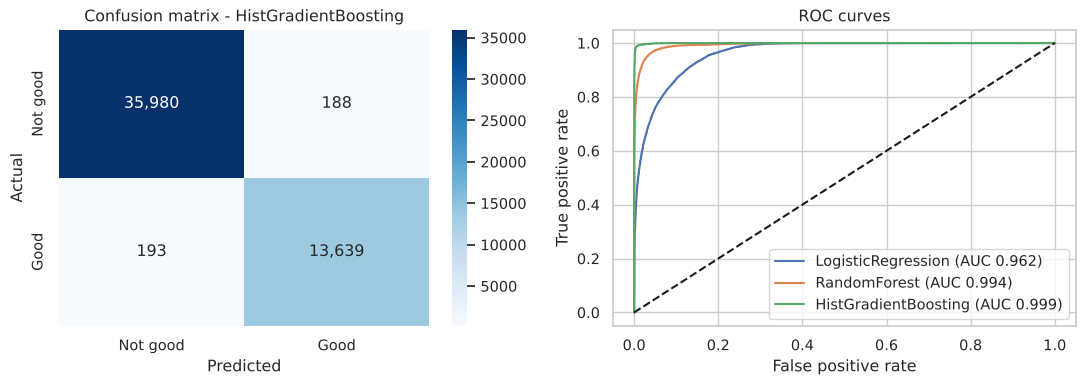

In [ ]:
best_clf = clf_results.f1.idxmax(); pipe_c, pred_c, proba_c = clf_fitted[best_clf]
print("Best classifier:", best_clf, "| majority-class baseline accuracy:", round(max(y_cls.mean(), 1 - y_cls.mean()), 4))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(ycte, pred_c); sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax[0], xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"]); ax[0].set(title=f"Confusion matrix - {best_clf}", xlabel="Predicted", ylabel="Actual")
for n_, (_, _, pr) in clf_fitted.items():
    fpr, tpr, _ = roc_curve(ycte, pr); ax[1].plot(fpr, tpr, label=f"{n_} (AUC {roc_auc_score(ycte, pr):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate"); ax[1].legend(); plt.tight_layout(); plt.show()

### 5.2 Regression

Best regressor: HistGradientBoosting


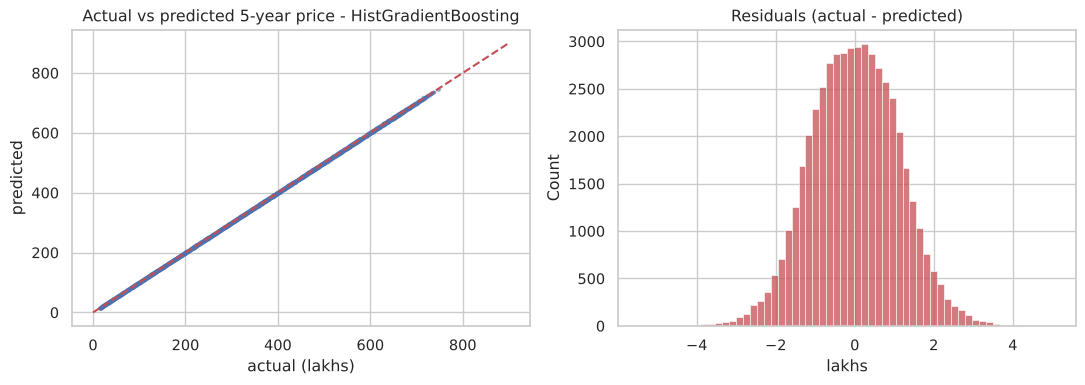

In [ ]:
best_reg = reg_results.rmse.idxmin(); pipe_r, pred_r = reg_fitted[best_reg]
print("Best regressor:", best_reg)
idx = yrte.sample(5000, random_state=1).index
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yrte.loc[idx], pd.Series(pred_r, index=yrte.index).loc[idx], s=3, alpha=.3); ax[0].plot([0, 900], [0, 900], "r--"); ax[0].set(title=f"Actual vs predicted 5-year price - {best_reg}", xlabel="actual (lakhs)", ylabel="predicted")
sns.histplot(yrte - pred_r, bins=60, ax=ax[1], color=PAL[3]); ax[1].set(title="Residuals (actual - predicted)", xlabel="lakhs"); plt.tight_layout(); plt.show()

**Reading the scores.** High accuracy and R² here are expected, not impressive: the labels are made from the same inputs by fixed rules, so the models recover the rules. Even Ridge reaches R² ≈ 0.999 because the 5-year price is the current price times a growth factor of about 1.26–1.57. These metrics demonstrate the pipeline, not real-world predictive power.

### 5.3 Feature importance (permutation importance on the test set)

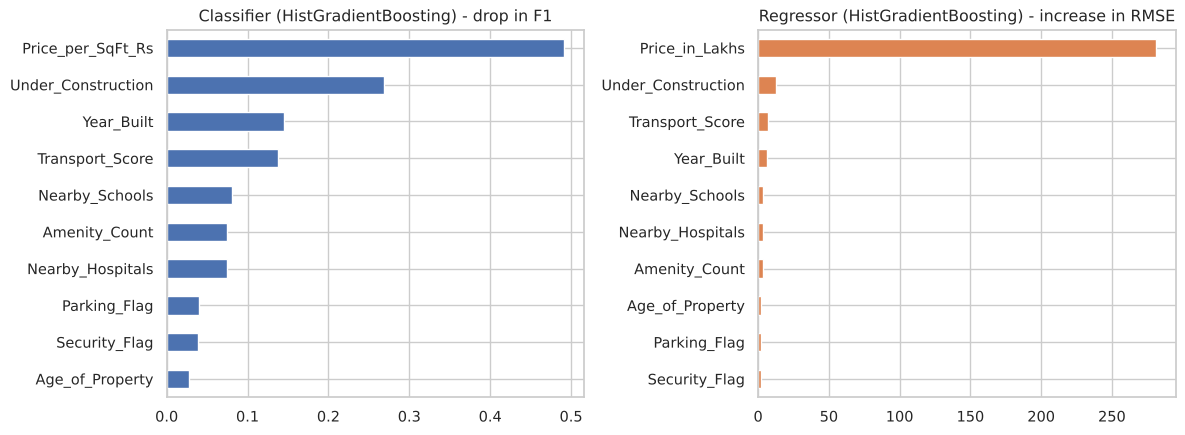

In [ ]:
sub = Xte.sample(8000, random_state=1).index
imp_c = pd.Series(permutation_importance(pipe_c, Xte.loc[sub], y_cls.loc[sub], n_repeats=3, random_state=SEED, scoring="f1").importances_mean, index=FEATURES).sort_values(ascending=False)
imp_r = pd.Series(permutation_importance(pipe_r, Xte.loc[sub], y_reg.loc[sub], n_repeats=3, random_state=SEED, scoring="neg_root_mean_squared_error").importances_mean, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
imp_c.head(10)[::-1].plot.barh(ax=ax[0], color=PAL[0], title=f"Classifier ({best_clf}) - drop in F1"); imp_r.head(10)[::-1].plot.barh(ax=ax[1], color=PAL[1], title=f"Regressor ({best_reg}) - increase in RMSE")
plt.tight_layout(); plt.show()

**Reading:** the classifier relies on price per sq ft (the value test), under-construction status, year built, transport, schools, hospitals and amenities, which are exactly the label rules. The regressor is dominated by the current price, then the growth drivers. This confirms the models learned the rules.

## 6. Save models & make a prediction

In [ ]:
joblib.dump(pipe_c, "models/best_classifier.joblib"); joblib.dump(pipe_r, "models/best_regressor.joblib")
print("Saved models/best_classifier.joblib and models/best_regressor.joblib")

# example: score one new property
new = pd.DataFrame([dict(State="Karnataka", City="Bangalore", Property_Type="Apartment", Furnished_Status="Semi-furnished", Facing="East", Owner_Type="Builder",
                         BHK=3, Size_in_SqFt=1800, Price_in_Lakhs=120.0, Year_Built=2018, Floor_No=4, Total_Floors=12, Nearby_Schools=7, Nearby_Hospitals=6,
                         Transport_Score=3, Parking_Flag=1, Security_Flag=1, Amenity_Count=3, Under_Construction=1)])
new["Age_of_Property"] = CURRENT_YEAR - new.Year_Built
new["Price_per_SqFt_Rs"] = new.Price_in_Lakhs * 1e5 / new.Size_in_SqFt
new["School_Density_Score"] = new.Nearby_Schools; new["Hospital_Density_Score"] = new.Nearby_Hospitals
new["Price_per_BHK"] = new.Price_in_Lakhs / new.BHK; new["Size_per_BHK"] = new.Size_in_SqFt / new.BHK; new["Floor_Ratio"] = new.Floor_No / new.Total_Floors
p = pipe_c.predict_proba(new[FEATURES])[0, 1]; f5 = pipe_r.predict(new[FEATURES])[0]
print(f"Good Investment? {'YES' if p >= .5 else 'NO'} (probability {p:.1%})")
print(f"Estimated price after 5 years: {f5:.1f} lakhs (today {new.Price_in_Lakhs[0]:.1f}; implied growth {(f5/new.Price_in_Lakhs[0])**(1/5)-1:.1%} a year)")

Saved models/best_classifier.joblib and models/best_regressor.joblib
Good Investment? YES (probability 100.0%)
Estimated price after 5 years: 181.3 lakhs (today 120.0; implied growth 8.6% a year)


## 7. Conclusions
1. **Data:** 250,000 clean records (no missing values or duplicates). Price per sq ft recomputed in rupees; 46.5% of rows have Floor_No above Total_Floors (flagged).
2. **EDA:** almost no attribute explains price. State, city, property type, furnishing, facing, parking, amenities, schools, hospitals and transport each move price per sq ft by under ~3%, mostly not significantly. The only strong pattern is mechanical (price per sq ft falls with size). The data looks synthetic.
3. **Models:** the Good Investment classifier and the 5-year price regressor both score very high because the targets are rule-based; treat them as a working pipeline, not proof of market-predictive power.
4. **Next steps:** replace the assumed growth rule with real multi-year price data; add crime, infrastructure-project and rental-yield data; validate on real listings.
5. **Not financial advice.**

*XGBoost / MLflow:* if installed, this notebook trains XGBoost and logs every run to MLflow automatically (`mlflow ui` to compare runs).